## Lista 7 - Exercício de Mineração de texto

#### Questão 1

Use o dataset "tweets_trump.csv", que contém todos os tweets do D. Trump e faça o que é pedido abaixo.

a) Utilizando o texto dos tweets identifique 5 tópicos latentes com o LDA, com um preprocessamento básico -- remoção de urls, remoção de pontuação, stemming e conversão para minúsculo.

b) Avalie os tópicos encontrados. Algum preprocessamento a mais poderia ser útil para a produção de um melhor resultado?


In [17]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Baixar stopwords
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')


# Carregar dataset
df = pd.read_csv('tweets_trump.csv', encoding='latin-1')

# Pré-processamento básico
def preprocess_text(text):
    text = text.lower()  # Converter para minúsculo
    text = re.sub(r"http\S+|www\S+", "", text)  # Remover URLs
    text = re.sub(r"[^\w\s]", "", text)  # Remover pontuação
    tokens = word_tokenize(text)  # Tokenização
    tokens = [PorterStemmer().stem(word) for word in tokens if word not in stopwords.words('english')]  # Stemming e remoção de stopwords
    return " ".join(tokens)

df['processed_text'] = df['text'].astype(str).apply(preprocess_text)

# Vetorização
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df['processed_text'])

# Modelo LDA com 5 tópicos
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(X)

# Exibir os tópicos
words = vectorizer.get_feature_names_out()
for i, topic in enumerate(lda.components_):
    print(f"Tópico {i+1}: ", " ".join([words[i] for i in topic.argsort()[-10:]]))


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Tópico 1:  news job want state get countri us great peopl amp
Tópico 2:  vote foxnew poll via presid donald thank rt realdonaldtrump trump
Tópico 3:  countri great true one best need presid run trump realdonaldtrump
Tópico 4:  make tonight new see night amp love realdonaldtrump great thank
Tópico 5:  great whitehous democrat american amp today hous realdonaldtrump presid rt


Aparentemente os tópicos encontrados fazem sentido o primeiro podendo estar relacionado com discurso de econimia e ou politicas públicas... o segundo com campanhas eleitorais... o terceiro com discursos presidencialistas e nacionalistas... o quarto com discursos a apoiadores talvez e o último indica relação com debates sobre politica.

Creio que uma melhoria possivel para melhorar o pré-processamento é remover termos aparentemente irrelevantes como "amp" e "rt" e também aplicar lematização em vez de stamming também pode ajudar pois termos com a mesma semantica são convertidos para sua forma "canonica" facilitando a analise...

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('tweets_trump.csv', encoding='latin-1')

# Print the first few rows to see the columns and data
print(df.head())

                    id                                               text  \
0    98454970654916608  Republicans and Democrats have both created ou...   
1  1234653427789070336  I was thrilled to be back in the Great city of...   
2  1218010753434820614  RT @CBS_Herridge: READ: Letter to surveillance...   
3  1304875170860015617  The Unsolicited Mail In Ballot Scam is a major...   
4  1218159531554897920  RT @MZHemingway: Very friendly telling of even...   

  isRetweet isDeleted              device  favorites  retweets  \
0         f         f           TweetDeck         49       255   
1         f         f  Twitter for iPhone      73748     17404   
2         t         f  Twitter for iPhone          0      7396   
3         f         f  Twitter for iPhone      80527     23502   
4         t         f  Twitter for iPhone          0      9081   

                  date isFlagged  
0  2011-08-02 18:07:48         f  
1  2020-03-03 01:34:50         f  
2  2020-01-17 03:22:47         f  


## Questão 2

Use o dataset "tweets_trump.csv" e responda:

a) Qual o sentimento dos 5 tweets com maior número de retweets?

b) Faça uma análise do sentimento geral de todos os tweets. Para isso, visualize a distribuição de polaridade para embasar a sua resposta.

In [18]:
# a)
from transformers import pipeline

# Sort by the 'retweet_count' column in descending order and get the top 5
top_retweets_df = df.sort_values(by='retweets', ascending=False).head(5)

# Print the 'text' column of the top 5 tweets
print(top_retweets['text'])


print("\n--- Sentimento dos Top 5 Tweets Mais Retweetados ---")
print("\nTop 5 tweets mais retweetados:")
for i, text in enumerate(top_retweets_df['text']):
    print(f"{i+1}. {text}")

sentiment_pipeline = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")
sentiments_top_5 = sentiment_pipeline(top_retweets_df['text'].tolist())

print("\nAnálise de Sentimento:")
for i, (tweet_text, sentiment) in enumerate(zip(top_retweets_df['text'], sentiments_top_5)):
    print(f"\nTweet {i+1}: {tweet_text}")
    print(f"Sentimento: {sentiment['label']} | Score: {sentiment['score']:.4f}")


11759    Tonight, @FLOTUS and I tested positive for COV...
35620           #FraudNewsCNN #FNN https://t.co/WYUnHjjUjg
39347                   TODAY WE MAKE AMERICA GREAT AGAIN!
29598    Are you allowed to impeach a president for gro...
9080          RT @SpaceX: Liftoff! https://t.co/DRBfdUM7JA
Name: text, dtype: object

--- Sentimento dos Top 5 Tweets Mais Retweetados ---

Top 5 tweets mais retweetados:
1. Tonight, @FLOTUS and I tested positive for COVID-19. We will begin our quarantine and recovery process immediately. We will get through this TOGETHER!
2. #FraudNewsCNN #FNN https://t.co/WYUnHjjUjg
3. TODAY WE MAKE AMERICA GREAT AGAIN!
4. Are you allowed to impeach a president for gross incompetence?
5. RT @SpaceX: Liftoff! https://t.co/DRBfdUM7JA


Device set to use cpu



Análise de Sentimento:

Tweet 1: Tonight, @FLOTUS and I tested positive for COVID-19. We will begin our quarantine and recovery process immediately. We will get through this TOGETHER!
Sentimento: POSITIVE | Score: 0.9905

Tweet 2: #FraudNewsCNN #FNN https://t.co/WYUnHjjUjg
Sentimento: NEGATIVE | Score: 0.9986

Tweet 3: TODAY WE MAKE AMERICA GREAT AGAIN!
Sentimento: POSITIVE | Score: 0.9999

Tweet 4: Are you allowed to impeach a president for gross incompetence?
Sentimento: NEGATIVE | Score: 0.9963

Tweet 5: RT @SpaceX: Liftoff! https://t.co/DRBfdUM7JA
Sentimento: NEGATIVE | Score: 0.6063


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...



Processando o sentimento de 56571 tweets...
Processados 0/56571 tweets
Processados 1000/56571 tweets
Processados 2000/56571 tweets
Processados 3000/56571 tweets
Processados 4000/56571 tweets
Processados 5000/56571 tweets
Processados 6000/56571 tweets
Processados 7000/56571 tweets
Processados 8000/56571 tweets
Processados 9000/56571 tweets
Processados 10000/56571 tweets
Processados 11000/56571 tweets
Processados 12000/56571 tweets
Processados 13000/56571 tweets
Processados 14000/56571 tweets
Processados 15000/56571 tweets
Processados 16000/56571 tweets
Processados 17000/56571 tweets
Processados 18000/56571 tweets
Processados 19000/56571 tweets
Processados 20000/56571 tweets
Processados 21000/56571 tweets
Processados 22000/56571 tweets
Processados 23000/56571 tweets
Processados 24000/56571 tweets
Processados 25000/56571 tweets
Processados 26000/56571 tweets
Processados 27000/56571 tweets
Processados 28000/56571 tweets
Processados 29000/56571 tweets
Processados 30000/56571 tweets
Process

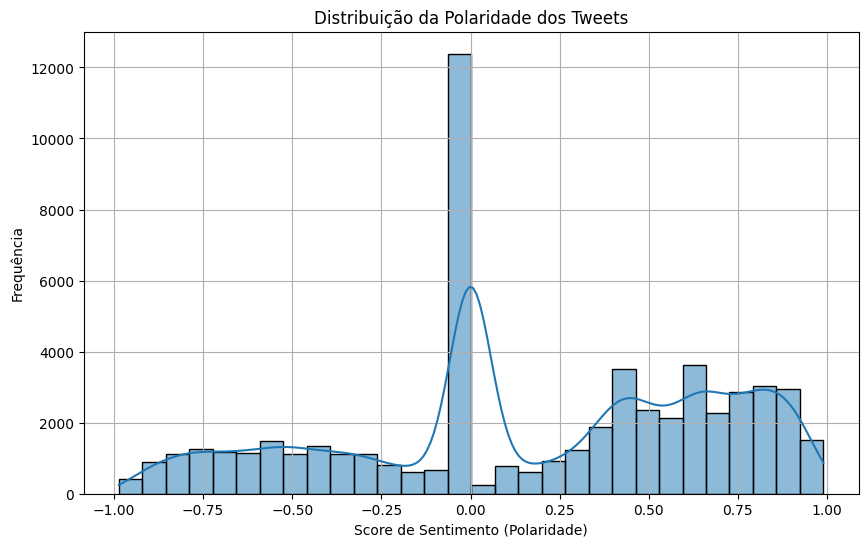


--- Sumário do Sentimento Geral ---
Polaridade Média: 0.1825
Polaridade Mediana: 0.1984
Tweets Positivos (> 0.05): 29788 (52.66%)
Tweets Negativos (< -0.05): 14386 (25.43%)
Tweets Neutros (entre -0.05 e 0.05): 12397 (21.91%)


In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

# Baixar os recursos necessários do NLTK
nltk.download('vader_lexicon')

# Carregar o dataset e garantir que os tweets estejam em formato string
df = pd.read_csv('tweets_trump.csv', encoding='latin-1')
df['text'] = df['text'].astype(str)
all_tweets_text = df['text'].tolist()

# Inicializar o analisador de sentimento VADER
sia = SentimentIntensityAnalyzer()

print(f"\nProcessando o sentimento de {len(all_tweets_text)} tweets...")

# Processar os tweets
all_sentiments_scores = []
for i, text in enumerate(all_tweets_text):
    score = sia.polarity_scores(text)['compound']
    all_sentiments_scores.append(score)
    if i % 1000 == 0:
        print(f"Processados {i}/{len(all_tweets_text)} tweets")

# Plotar a distribuição da polaridade dos tweets
plt.figure(figsize=(10, 6))
sns.histplot(all_sentiments_scores, bins=30, kde=True)
plt.title("Distribuição da Polaridade dos Tweets")
plt.xlabel("Score de Sentimento (Polaridade)")
plt.ylabel("Frequência")
plt.grid(True)
plt.show()

# Exibir estatísticas resumidas para embasar a análise
scores_series = pd.Series(all_sentiments_scores)
avg_polarity = scores_series.mean()
median_polarity = scores_series.median()
limiar_positivo = 0.05
limiar_negativo = -0.05

positive = (scores_series > limiar_positivo).sum()
negative = (scores_series < limiar_negativo).sum()
neutral  = ((scores_series >= limiar_negativo) & (scores_series <= limiar_positivo)).sum()
total    = len(scores_series)

print("\n--- Sumário do Sentimento Geral ---")
print(f"Polaridade Média: {avg_polarity:.4f}")
print(f"Polaridade Mediana: {median_polarity:.4f}")
print(f"Tweets Positivos (> {limiar_positivo}): {positive} ({positive/total*100:.2f}%)")
print(f"Tweets Negativos (< {limiar_negativo}): {negative} ({negative/total*100:.2f}%)")
print(f"Tweets Neutros (entre {limiar_negativo} e {limiar_positivo}): {neutral} ({neutral/total*100:.2f}%)")
